In [ ]:
"""
FestiCast - Phase 1 (Synopsis) EDA
Basic visual exploration ONLY - no forecasting models (as required by the guidelines).

Usage:
    1. Download train.csv from Kaggle:
       https://www.kaggle.com/c/demand-forecasting-kernels-only/data
    2. Put it next to this script (or pass the path):
       python eda_synopsis.py train.csv
Outputs (in ./figs): fig1_line.png, fig2_missing.png, fig3_decomp.png,
                     fig4_seasonal.png, snapshot.csv
Also prints every number used on the dataset slide - copy them from the console.
"""
import os
import sys

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.tsa.seasonal import STL

# Safely detect if we are running in a notebook/ipykernel to avoid parsing notebook arguments
is_ipykernel = any("ipykernel" in arg for arg in sys.argv) or (len(sys.argv) > 1 and sys.argv[1] == "-f")
PATH = "train.csv" if is_ipykernel or len(sys.argv) <= 1 else sys.argv[1]
OUT = "figs"
os.makedirs(OUT, exist_ok=True)

TERRACOTTA, SAGE, DARK = "#B85042", "#A7BEAE", "#3A2A25"
plt.rcParams.update({
    "figure.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": DARK, "axes.labelcolor": DARK, "xtick.color": DARK,
    "ytick.color": DARK, "font.size": 10,
})

# ------------------------------------------------------------------ load
df = pd.read_csv(PATH, parse_dates=["date"])
print("=" * 60, "\nDATASET FACTS (copy into slide 5)\n" + "=" * 60)
print(f"Rows (store-item-day records): {len(df):,}")
print(f"Columns: {list(df.columns)}")
print(f"Date range: {df['date'].min().date()} -> {df['date'].max().date()}")
print(f"Stores: {df['store'].nunique()} | Items: {df['item'].nunique()}")
print(f"Duplicate (date, store, item) rows: {df.duplicated(['date', 'store', 'item']).sum()}")
print("Missing values per column:\n", df.isna().sum().to_string())
print(f"Sales min/median/mean/max: {df['sales'].min()} / {df['sales'].median()} / "
      f"{df['sales'].mean():.1f} / {df['sales'].max()}")

# snapshot (5-10 rows required on slide)
snap = df.sort_values(["date", "store", "item"]).head(8)
snap.to_csv(f"{OUT}/snapshot.csv", index=False)
print("\nSNAPSHOT (first 8 rows):\n", snap.to_string(index=False))

# daily total series (the series we analyse in the synopsis)
daily = df.groupby("date")["sales"].sum().sort_index()
full_idx = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
missing_dates = full_idx.difference(daily.index)
print(f"\nDaily points: {len(daily):,} | expected: {len(full_idx):,} | "
      f"missing dates: {len(missing_dates)}")
print("Frequency: daily (regular)" if len(missing_dates) == 0 else "WARNING: gaps found")
daily = daily.reindex(full_idx)

# ------------------------------------------------------------------ Fig 1: line plot
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(daily.index, daily.values, color=SAGE, lw=0.7, label="Daily total sales")
ax.plot(daily.rolling(30, center=True).mean(), color=TERRACOTTA, lw=1.8, label="30-day moving avg")
ax.set_title("Daily total sales (all stores & items)", color=DARK, loc="left", fontweight="bold")
ax.set_ylabel("Units sold")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(f"{OUT}/fig1_line.png")
plt.close(fig)

# ------------------------------------------------------------------ Fig 2: missing data
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2), gridspec_kw={"width_ratios": [1, 2]})
miss = df.isna().sum()
axes[0].barh(miss.index, miss.values, color=TERRACOTTA)
axes[0].set_title("Missing values / column", loc="left", fontweight="bold", color=DARK, fontsize=9)
axes[0].set_xlim(0, max(1, miss.max()))
axes[0].set_xlabel("count")
present = pd.Series(1, index=full_idx)
present.loc[missing_dates] = 0
axes[1].fill_between(full_idx, 0, present.values, step="mid", color=SAGE)
axes[1].set_yticks([0, 1], ["missing", "present"])
axes[1].set_title(f"Date completeness ({len(missing_dates)} missing of {len(full_idx):,})",
                  loc="left", fontweight="bold", color=DARK, fontsize=9)
fig.tight_layout()
fig.savefig(f"{OUT}/fig2_missing.png")
plt.close(fig)

# ------------------------------------------------------------------ Fig 3: decomposition (visual only)
weekly = daily.resample("W").sum()
res = STL(weekly, period=52, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(7, 5), sharex=True)
for ax, (name, s) in zip(axes, [("Observed", weekly), ("Trend", res.trend),
                                 ("Seasonal (yearly)", res.seasonal), ("Residual", res.resid)]):
    ax.plot(s, color=TERRACOTTA if name != "Observed" else DARK, lw=1)
    ax.set_ylabel(name, fontsize=8)
axes[0].set_title("STL decomposition of weekly total sales", loc="left", fontweight="bold", color=DARK)
fig.tight_layout()
fig.savefig(f"{OUT}/fig3_decomp.png")
plt.close(fig)

# ------------------------------------------------------------------ Fig 4: seasonal views + histogram
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
dow = daily.groupby(daily.index.dayofweek).mean()
axes[0].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow.values, color=SAGE)
axes[0].set_title("Avg sales by weekday", loc="left", fontweight="bold", fontsize=9, color=DARK)
monthly = daily.groupby([daily.index.year, daily.index.month]).mean().unstack(0)
monthly.plot(ax=axes[1], lw=1.2, legend=True)
axes[1].set_title("Seasonal plot: avg by month, per year", loc="left", fontweight="bold", fontsize=9, color=DARK)
axes[1].set_xlabel("month")
axes[1].legend(frameon=False, fontsize=7, ncol=2)
axes[2].hist(daily.dropna(), bins=40, color=TERRACOTTA)
axes[2].set_title("Distribution of daily sales", loc="left", fontweight="bold", fontsize=9, color=DARK)
fig.tight_layout()
fig.savefig(f"{OUT}/fig4_seasonal.png")
plt.close(fig)

print(f"\nDone. Figures + snapshot saved in ./{OUT}/")

DATASET FACTS (copy into slide 5)
Rows (store-item-day records): 913,000
Columns: ['date', 'store', 'item', 'sales']
Date range: 2013-01-01 -> 2017-12-31
Stores: 10 | Items: 50
Duplicate (date, store, item) rows: 0
Missing values per column:
 date     0
store    0
item     0
sales    0
Sales min/median/mean/max: 0 / 47.0 / 52.3 / 231

SNAPSHOT (first 8 rows):
       date  store  item  sales
2013-01-01      1     1     13
2013-01-01      1     2     33
2013-01-01      1     3     15
2013-01-01      1     4     10
2013-01-01      1     5     11
2013-01-01      1     6     31
2013-01-01      1     7     25
2013-01-01      1     8     33

Daily points: 1,826 | expected: 1,826 | missing dates: 0
Frequency: daily (regular)

Done. Figures + snapshot saved in ./figs/


In [ ]:
#!/usr/bin/env python3
"""
eda_synopsis.py - Basic exploratory analysis for the Kaggle
"Store Item Demand Forecasting Challenge" train.csv (date, store, item, sales).

No forecasting models are fitted. The script prints dataset facts and saves:
    figs/fig1_line.png        daily total sales + 30-day rolling mean   (slide 6, box 1)
    figs/fig2_missing.png     missing-data / duplicates / completeness  (slide 6, box 2)
    figs/fig3_decomp.png      STL / MSTL decomposition                  (slide 6, box 3)
    figs/fig4_seasonal.png    weekday and month-of-year seasonal plots
    figs/snapshot_table.png   summary table image
    figs/snapshot_table.csv   same table as CSV

Usage:
    python eda_synopsis.py                       # expects train.csv next to the script
    python eda_synopsis.py --data path/to/train.csv --out figs

Requires: pandas, numpy, matplotlib, statsmodels
    pip install pandas numpy matplotlib statsmodels
"""

import argparse
import os
import sys

import matplotlib
matplotlib.use("Agg")  # no display needed
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from statsmodels.tsa.seasonal import STL
except ImportError:
    sys.exit("statsmodels is required: pip install statsmodels")

try:  # MSTL exists in statsmodels >= 0.14
    from statsmodels.tsa.seasonal import MSTL
except ImportError:
    MSTL = None

PALETTE = {"main": "#B5483D", "dark": "#3B2A26", "soft": "#E8A79F", "grey": "#8C8C8C"}
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 200,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "font.size": 10,
})


def hr(title):
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)


# ----------------------------------------------------------------------
# 1. Load + dataset facts (slide 5 numbers)
# ----------------------------------------------------------------------
def load(path):
    if not os.path.exists(path):
        sys.exit(f"Cannot find '{path}'. Download train.csv from Kaggle and pass --data.")
    df = pd.read_csv(path)
    needed = {"date", "store", "item", "sales"}
    if not needed.issubset(df.columns):
        sys.exit(f"Expected columns {sorted(needed)}, found {list(df.columns)}")
    df["date"] = pd.to_datetime(df["date"])
    return df.sort_values(["date", "store", "item"]).reset_index(drop=True)


def dataset_facts(df):
    hr("DATASET FACTS (check these against slide 5)")
    n_days = df["date"].nunique()
    n_store, n_item = df["store"].nunique(), df["item"].nunique()
    full_range = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
    missing_dates = full_range.difference(df["date"].unique())
    dup = df.duplicated(["date", "store", "item"]).sum()

    print(f"Rows                 : {len(df):,}")
    print(f"Columns              : {list(df.columns)}")
    print(f"Date range           : {df['date'].min().date()} -> {df['date'].max().date()}")
    print(f"Distinct days        : {n_days:,}  (calendar days in range: {len(full_range):,})")
    print(f"Stores / Items       : {n_store} / {n_item}  -> {n_store * n_item} store-item series")
    print(f"Expected rows        : {n_days * n_store * n_item:,}")
    print(f"Missing values       : {int(df.isna().sum().sum())}")
    print(f"Duplicate keys       : {int(dup)}")
    print(f"Missing calendar days: {len(missing_dates)}")
    print(f"Sales  min/median/mean/max : {df['sales'].min()} / {df['sales'].median():.1f} / "
          f"{df['sales'].mean():.2f} / {df['sales'].max()}")
    print(f"Zero-sales rows      : {(df['sales'] == 0).sum():,}")
    return full_range, missing_dates, dup


def daily_total(df, full_range):
    s = df.groupby("date")["sales"].sum().reindex(full_range)
    s.index.name = "date"
    return s.interpolate()  # only matters if calendar days were missing


# ----------------------------------------------------------------------
# 2. Figures
# ----------------------------------------------------------------------
def fig1_line(daily, out):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(daily.index, daily.values, color=PALETTE["soft"], lw=0.7, label="Daily total")
    ax.plot(daily.index, daily.rolling(30, center=True).mean(), color=PALETTE["main"],
            lw=2, label="30-day rolling mean")
    ax.set_title("Fig 1: Daily total sales (all stores, all items)")
    ax.set_xlabel("Date")
    ax.set_ylabel("Units sold")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig1_line.png"))
    plt.close(fig)


def fig2_missing(df, missing_dates, dup, out):
    n_days = df["date"].nunique()
    counts = df.groupby(["store", "item"]).size().unstack("item")
    completeness = counts / n_days * 100

    fig, (a, b) = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={"width_ratios": [1, 1.6]})

    checks = {
        "Null: date": df["date"].isna().sum(),
        "Null: store": df["store"].isna().sum(),
        "Null: item": df["item"].isna().sum(),
        "Null: sales": df["sales"].isna().sum(),
        "Duplicate keys": dup,
        "Missing days": len(missing_dates),
    }
    a.barh(list(checks.keys()), list(checks.values()), color=PALETTE["main"])
    a.invert_yaxis()
    a.set_xlim(0, max(1, max(checks.values())) * 1.2)
    for i, v in enumerate(checks.values()):
        a.text(v, i, f" {int(v)}", va="center")
    a.set_title("Issue counts")

    im = b.imshow(completeness.values, aspect="auto", cmap="Reds", vmin=0, vmax=100)
    b.set_xticks(range(0, completeness.shape[1], 5))
    b.set_xticklabels(completeness.columns[::5])
    b.set_yticks(range(completeness.shape[0]))
    b.set_yticklabels(completeness.index)
    b.set_xlabel("Item")
    b.set_ylabel("Store")
    b.set_title("Completeness per store-item (% of days present)")
    fig.colorbar(im, ax=b, fraction=0.04)

    fig.suptitle("Fig 2: Missing-data check", fontweight="bold")
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig2_missing.png"))
    plt.close(fig)


def decompose(daily):
    """Return dict of components. MSTL (weekly + yearly) if available, else STL weekly."""
    y = daily.astype(float)
    if MSTL is not None and len(y) >= 2 * 365:
        try:
            res = MSTL(y, periods=(7, 365)).fit()
            seas = pd.DataFrame(res.seasonal, index=y.index)
            seas.columns = ["weekly", "yearly"]
            return {"observed": y, "trend": res.trend, "weekly": seas["weekly"],
                    "yearly": seas["yearly"], "resid": res.resid, "method": "MSTL (7, 365)"}
        except Exception as e:  # fall through to STL
            print(f"[warn] MSTL failed ({e}); falling back to STL.")
    res = STL(y, period=7, robust=True).fit()
    out = {"observed": y, "trend": res.trend, "weekly": res.seasonal, "resid": res.resid,
           "method": "STL (period 7)"}
    if len(y) >= 2 * 365:  # estimate yearly pattern from the weekly-adjusted trend
        res_y = STL(res.trend + res.resid, period=365, robust=True).fit()
        out["yearly"] = res_y.seasonal
        out["trend"] = res_y.trend
        out["resid"] = res_y.resid
        out["method"] = "STL (7) then STL (365)"
    return out


def fig3_decomp(comp, out):
    keys = ["observed", "trend", "weekly"] + (["yearly"] if "yearly" in comp else []) + ["resid"]
    titles = {"observed": "Observed", "trend": "Trend", "weekly": "Weekly seasonality",
              "yearly": "Yearly seasonality", "resid": "Residual"}
    fig, axes = plt.subplots(len(keys), 1, figsize=(8, 1.6 * len(keys) + 1), sharex=True)
    for ax, k in zip(axes, keys):
        s = comp[k]
        if k == "resid":
            ax.plot(s.index, s.values, color=PALETTE["grey"], lw=0.6)
            thr = 3 * 1.4826 * np.median(np.abs(s - s.median()))
            flag = s[np.abs(s - s.median()) > thr]
            ax.scatter(flag.index, flag.values, s=10, color=PALETTE["main"], zorder=3)
            ax.axhline(0, color=PALETTE["dark"], lw=0.5)
        else:
            ax.plot(s.index, s.values, color=PALETTE["main"], lw=0.8 if k != "trend" else 1.6)
        ax.set_ylabel(titles[k], fontsize=8)
    axes[0].set_title(f"Fig 3: {comp['method']} decomposition of daily total sales")
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig3_decomp.png"))
    plt.close(fig)


def fig4_seasonal(daily, out):
    d = daily.to_frame("sales")
    dow = d.groupby(d.index.dayofweek)["sales"].mean()
    dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

    monthly = d["sales"].resample("MS").sum().to_frame("sales")
    monthly["year"], monthly["month"] = monthly.index.year, monthly.index.month
    piv = monthly.pivot(index="month", columns="year", values="sales")

    fig, (a, b) = plt.subplots(1, 2, figsize=(10, 4.5))
    a.bar(dow.index, dow.values, color=PALETTE["main"])
    a.set_ylim(dow.min() * 0.9, dow.max() * 1.03)
    a.set_title("Average daily sales by weekday")
    a.set_ylabel("Units sold")

    cmap = plt.get_cmap("Reds")
    for i, yr in enumerate(piv.columns):
        b.plot(piv.index, piv[yr], marker="o", ms=3, lw=1.5,
               color=cmap(0.35 + 0.6 * i / max(1, len(piv.columns) - 1)), label=str(yr))
    b.set_xticks(range(1, 13))
    b.set_xticklabels(list("JFMAMJJASOND"))
    b.set_title("Monthly total sales by year")
    b.legend(frameon=False, ncol=2, fontsize=8)

    fig.suptitle("Fig 4: Seasonal plots", fontweight="bold")
    fig.tight_layout()
    fig.savefig(os.path.join(out, "fig4_seasonal.png"))
    plt.close(fig)
    return dow, piv


def snapshot_table(df, daily, out):
    snap = pd.DataFrame({
        "Metric": ["Rows", "Date range", "Days", "Stores", "Items", "Store-item series",
                   "Missing values", "Duplicate keys", "Mean sales / row", "Max sales / row",
                   "Mean daily total", "Max daily total"],
        "Value": [f"{len(df):,}",
                  f"{df['date'].min().date()} to {df['date'].max().date()}",
                  f"{df['date'].nunique():,}",
                  df["store"].nunique(), df["item"].nunique(),
                  df.groupby(["store", "item"]).ngroups,
                  int(df.isna().sum().sum()),
                  int(df.duplicated(["date", "store", "item"]).sum()),
                  f"{df['sales'].mean():.2f}", int(df["sales"].max()),
                  f"{daily.mean():,.0f}", f"{daily.max():,.0f}"],
    })
    snap.to_csv(os.path.join(out, "snapshot_table.csv"), index=False)

    fig, ax = plt.subplots(figsize=(6, 0.4 * len(snap) + 0.6))
    ax.axis("off")
    tbl = ax.table(cellText=snap.values, colLabels=snap.columns, loc="center", cellLoc="left")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    tbl.scale(1, 1.4)
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor("#DDDDDD")
        if r == 0:
            cell.set_facecolor(PALETTE["main"])
            cell.set_text_props(color="white", weight="bold")
    fig.tight_layout()
    fig.savefig(os.path.join(out, "snapshot_table.png"), bbox_inches="tight")
    plt.close(fig)


# ----------------------------------------------------------------------
# 3. Numbers to support your slide 6 observations / slide 7 claim
# ----------------------------------------------------------------------
def strength(component, resid):
    """Seasonal/trend strength (Wang, Smith & Hyndman): 1 - Var(R) / Var(C + R)."""
    return max(0.0, 1 - np.var(resid) / np.var(component + resid))


def print_findings(daily, comp, dow, piv):
    hr("FINDINGS TO CHECK AGAINST YOUR PLOTS (slides 6 and 7)")
    yearly_mean = daily.resample("YS").mean()
    growth = yearly_mean.pct_change().dropna() * 100
    print("Mean daily total by year:")
    for yr, v in yearly_mean.items():
        print(f"  {yr.year}: {v:,.0f}")
    print("Year-on-year growth (%): " + ", ".join(f"{g:.1f}" for g in growth))
    t = np.arange(len(daily))
    slope = np.polyfit(t, comp["trend"].values, 1)[0]
    print(f"Trend slope: {slope:+.2f} units/day -> {'upward' if slope > 0 else 'downward'}")

    print(f"\nWeekday averages: peak {dow.idxmax()} ({dow.max():,.0f}), "
          f"low {dow.idxmin()} ({dow.min():,.0f}), "
          f"peak/low ratio {dow.max() / dow.min():.2f}")
    print(f"Weekly seasonality strength (0-1): {strength(comp['weekly'], comp['resid']):.2f}")
    if "yearly" in comp:
        by_month = piv.mean(axis=1)
        print(f"Yearly seasonality strength (0-1): {strength(comp['yearly'], comp['resid']):.2f}")
        print(f"Month with highest average sales: {int(by_month.idxmax())}, "
              f"lowest: {int(by_month.idxmin())}")
    else:
        print("Less than 2 years of data: yearly seasonality not estimated.")
    print(f"Trend strength (0-1): "
          f"{strength(comp['trend'], comp['resid']):.2f}")

    r = comp["resid"]
    thr = 3 * 1.4826 * np.median(np.abs(r - r.median()))
    flagged = r[np.abs(r - r.median()) > thr]
    print(f"\nResidual outliers (|resid| > 3 robust SD): {len(flagged)} of {len(r)} days "
          f"({len(flagged) / len(r) * 100:.1f}%)")
    if len(flagged):
        top = flagged.reindex(flagged.abs().sort_values(ascending=False).index).head(5)
        for dt, v in top.items():
            print(f"  {dt.date()} ({dt.day_name()}): {v:+,.0f}")


# ----------------------------------------------------------------------
def main():
    ap = argparse.ArgumentParser(description="EDA for Store Item Demand Forecasting train.csv")
    ap.add_argument("--data", default="train.csv", help="path to train.csv")
    ap.add_argument("--out", default="figs", help="output folder for figures")

    # Safely detect if we are running in an interactive Jupyter / Colab environment
    is_ipykernel = any("ipykernel" in arg for arg in sys.argv) or (len(sys.argv) > 1 and sys.argv[1] == "-f")
    if is_ipykernel:
        args = ap.parse_args([])
    else:
        args = ap.parse_args()

    os.makedirs(args.out, exist_ok=True)
    df = load(args.data)
    full_range, missing_dates, dup = dataset_facts(df)
    daily = daily_total(df, full_range)

    fig1_line(daily, args.out)
    fig2_missing(df, missing_dates, dup, args.out)
    comp = decompose(daily)
    fig3_decomp(comp, args.out)
    dow, piv = fig4_seasonal(daily, args.out)
    snapshot_table(df, daily, args.out)
    print_findings(daily, comp, dow, piv)

    hr("SAVED")
    for f in sorted(os.listdir(args.out)):
        print(f"  {os.path.join(args.out, f)}")


if __name__ == "__main__":
    main()


DATASET FACTS (check these against slide 5)
Rows                 : 913,000
Columns              : ['date', 'store', 'item', 'sales']
Date range           : 2013-01-01 -> 2017-12-31
Distinct days        : 1,826  (calendar days in range: 1,826)
Stores / Items       : 10 / 50  -> 500 store-item series
Expected rows        : 913,000
Missing values       : 0
Duplicate keys       : 0
Missing calendar days: 0
Sales  min/median/mean/max : 0 / 47.0 / 52.25 / 231
Zero-sales rows      : 1

FINDINGS TO CHECK AGAINST YOUR PLOTS (slides 6 and 7)
Mean daily total by year:
  2013: 21,757
  2014: 25,029
  2015: 26,128
  2016: 28,298
  2017: 29,408
Year-on-year growth (%): 15.0, 4.4, 8.3, 3.9
Trend slope: +5.10 units/day -> upward

Weekday averages: peak Sun (31,072), low Mon (20,715), peak/low ratio 1.50
Weekly seasonality strength (0-1): 0.99
Yearly seasonality strength (0-1): 1.00
Month with highest average sales: 7, lowest: 1
Trend strength (0-1): 0.99

Residual outliers (|resid| > 3 robust SD): 38

In [ ]:
#!/usr/bin/env python3
"""
make_figs.py - makes ONLY the three images for slide 6, sized to fit the boxes.

    figs/fig1_line.png      Fig 1: Daily sales line plot
    figs/fig2_missing.png   Fig 2: Missing-data check
    figs/fig3_decomp.png    Fig 3: STL decomposition

Run:
    pip install pandas numpy matplotlib statsmodels
    python make_figs.py                      # train.csv in the same folder
    python make_figs.py --data path/to/train.csv
"""

import argparse
import os
import sys

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.seasonal import STL

try:
    from statsmodels.tsa.seasonal import MSTL
except ImportError:
    MSTL = None

RED, DARK, SOFT, GREY = "#B5483D", "#3B2A26", "#E8A79F", "#8C8C8C"
SIZE = (6, 5)  # about the same shape as the dashed boxes on the slide

plt.rcParams.update({
    "font.size": 11,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.dpi": 220,
})


def save(fig, out, name):
    fig.tight_layout()
    fig.savefig(os.path.join(out, name), facecolor="white")
    plt.close(fig)
    print("saved", os.path.join(out, name))


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="train.csv")
    ap.add_argument("--out", default="figs")

    # Safely detect if we are running in an interactive Jupyter / Colab environment
    is_ipykernel = any("ipykernel" in arg for arg in sys.argv) or (len(sys.argv) > 1 and sys.argv[1] == "-f")
    if is_ipykernel:
        a = ap.parse_args([])
    else:
        a = ap.parse_args()

    if not os.path.exists(a.data):
        sys.exit(f"Cannot find {a.data}. Put train.csv next to this script or use --data.")
    os.makedirs(a.out, exist_ok=True)

    df = pd.read_csv(a.data, parse_dates=["date"])
    days = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
    daily = df.groupby("date")["sales"].sum().reindex(days).interpolate()

    # ---------------- Fig 1: daily sales line plot ----------------
    fig, ax = plt.subplots(figsize=SIZE)
    ax.plot(daily.index, daily.values, color=SOFT, lw=0.6, label="Daily total")
    ax.plot(daily.index, daily.rolling(30, center=True).mean(), color=RED, lw=2,
            label="30-day mean")
    ax.set_title("Fig 1: Daily total sales")
    ax.set_xlabel("Date")
    ax.set_ylabel("Units sold")
    ax.legend(frameon=False, loc="upper left")
    save(fig, a.out, "fig1_line.png")

    # ---------------- Fig 2: missing-data check ----------------
    n_days = df["date"].nunique()
    comp = (df.groupby(["store", "item"]).size().unstack("item") / n_days * 100)
    nulls = int(df.isna().sum().sum())
    dups = int(df.duplicated(["date", "store", "item"]).sum())
    gaps = len(days.difference(df["date"].unique()))

    fig, ax = plt.subplots(figsize=SIZE)
    im = ax.imshow(comp.values, aspect="auto", cmap="Reds", vmin=0, vmax=100)
    ax.set_xticks(range(0, comp.shape[1], 5))
    ax.set_xticklabels(comp.columns[::5])
    ax.set_yticks(range(comp.shape[0]))
    ax.set_yticklabels(comp.index)
    ax.set_xlabel("Item")
    ax.set_ylabel("Store")
    fig.colorbar(im, ax=ax, label="% of days present")
    ax.set_title("Fig 2: Missing-data check")
    fig.text(0.5, 0.01,
             f"Nulls: {nulls}   Duplicate keys: {dups}   Missing days: {gaps}   "
             f"Rows: {len(df):,}",
             ha="center", fontsize=9, color=DARK)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig(os.path.join(a.out, "fig2_missing.png"), facecolor="white")
    plt.close(fig)
    print("saved", os.path.join(a.out, "fig2_missing.png"))

    # ---------------- Fig 3: decomposition ----------------
    y = daily.astype(float)
    if MSTL is not None and len(y) >= 730:
        r = MSTL(y, periods=(7, 365)).fit()
        s = pd.DataFrame(r.seasonal, index=y.index)
        trend, weekly, yearly, resid = r.trend, s.iloc[:, 0], s.iloc[:, 1], r.resid
        label = "MSTL"
    else:
        r = STL(y, period=7, robust=True).fit()
        r2 = STL(r.trend + r.resid, period=365, robust=True).fit()
        trend, weekly, yearly, resid = r2.trend, r.seasonal, r2.seasonal, r2.resid
        label = "STL"

    panels = [("Trend", trend), ("Yearly seasonality", yearly),
              ("Weekly seasonality", weekly), ("Residual", resid)]
    fig, axes = plt.subplots(4, 1, figsize=(6, 6), sharex=True)
    for ax, (name, s_) in zip(axes, panels):
        if name == "Residual":
            ax.plot(s_.index, s_.values, color=GREY, lw=0.5)
            thr = 3 * 1.4826 * np.median(np.abs(s_ - s_.median()))
            out_ = s_[np.abs(s_ - s_.median()) > thr]
            ax.scatter(out_.index, out_.values, s=8, color=RED, zorder=3)
            ax.axhline(0, color=DARK, lw=0.5)
        else:
            ax.plot(s_.index, s_.values, color=RED, lw=1.6 if name == "Trend" else 0.8)
        ax.set_ylabel(name, fontsize=8)
        ax.tick_params(labelsize=8)
    axes[0].set_title(f"Fig 3: {label} decomposition")
    save(fig, a.out, "fig3_decomp.png")


if __name__ == "__main__":
    main()

saved figs/fig1_line.png
saved figs/fig2_missing.png
saved figs/fig3_decomp.png


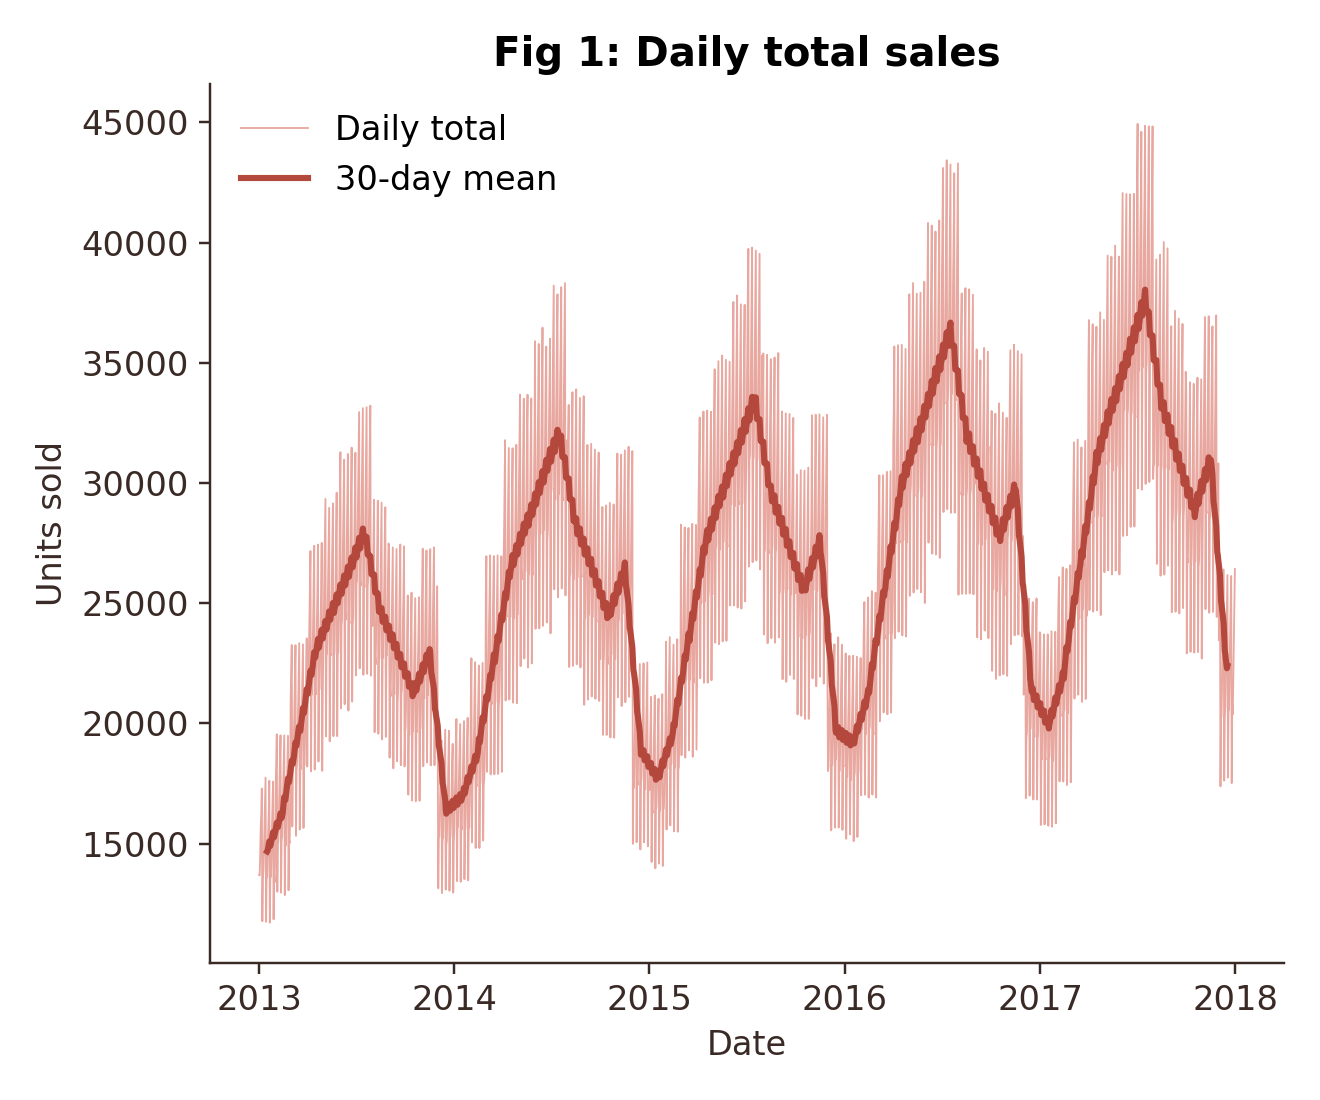

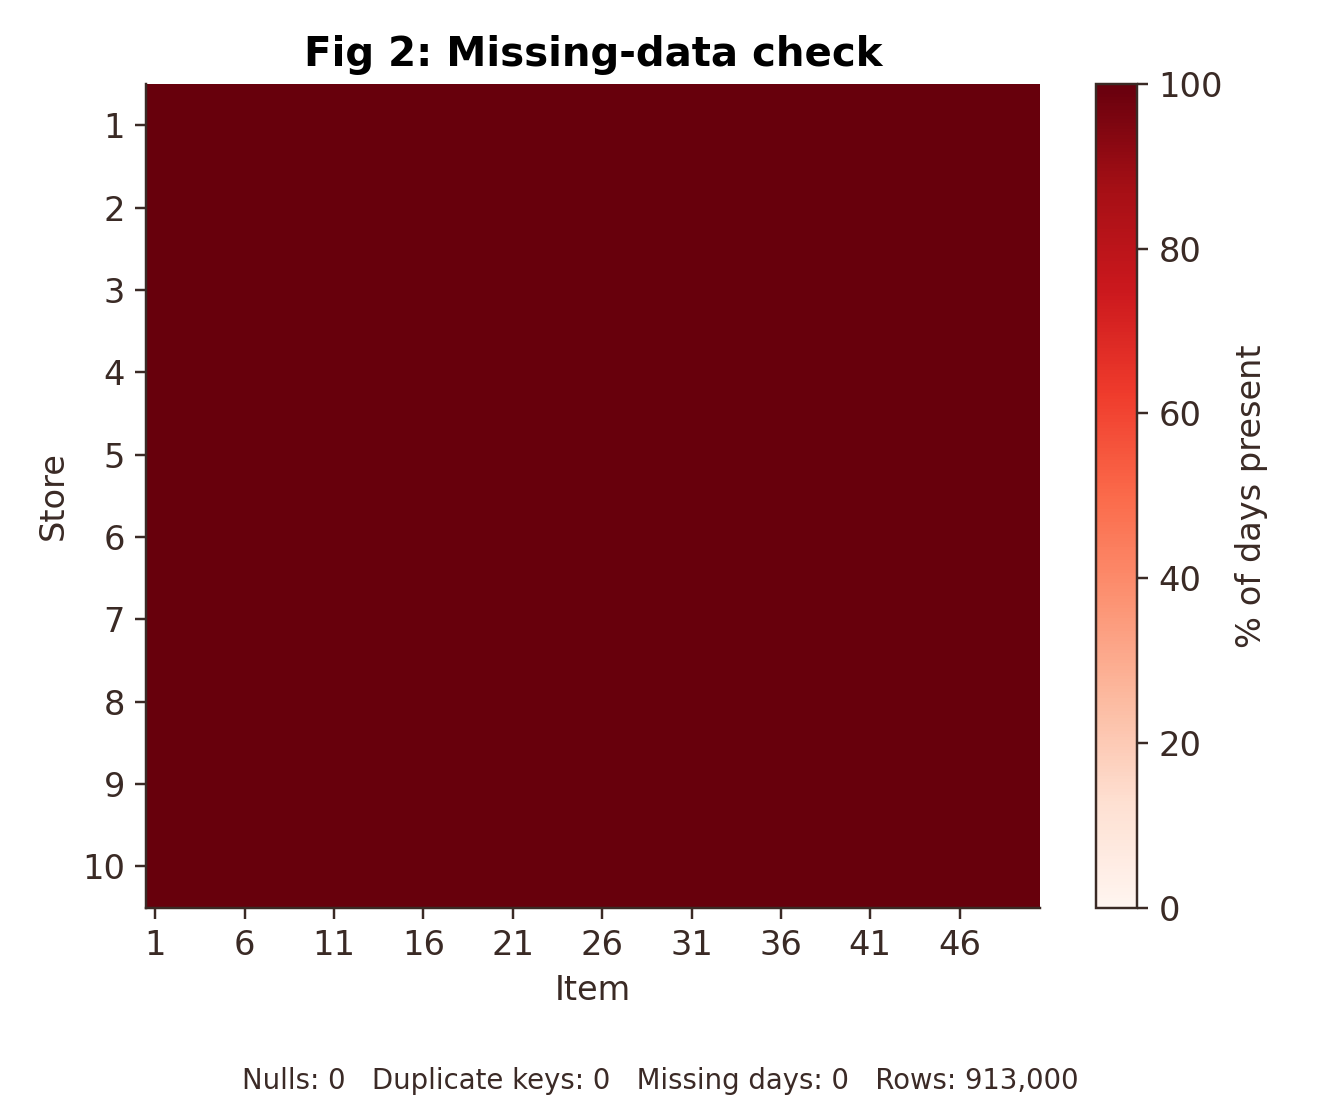

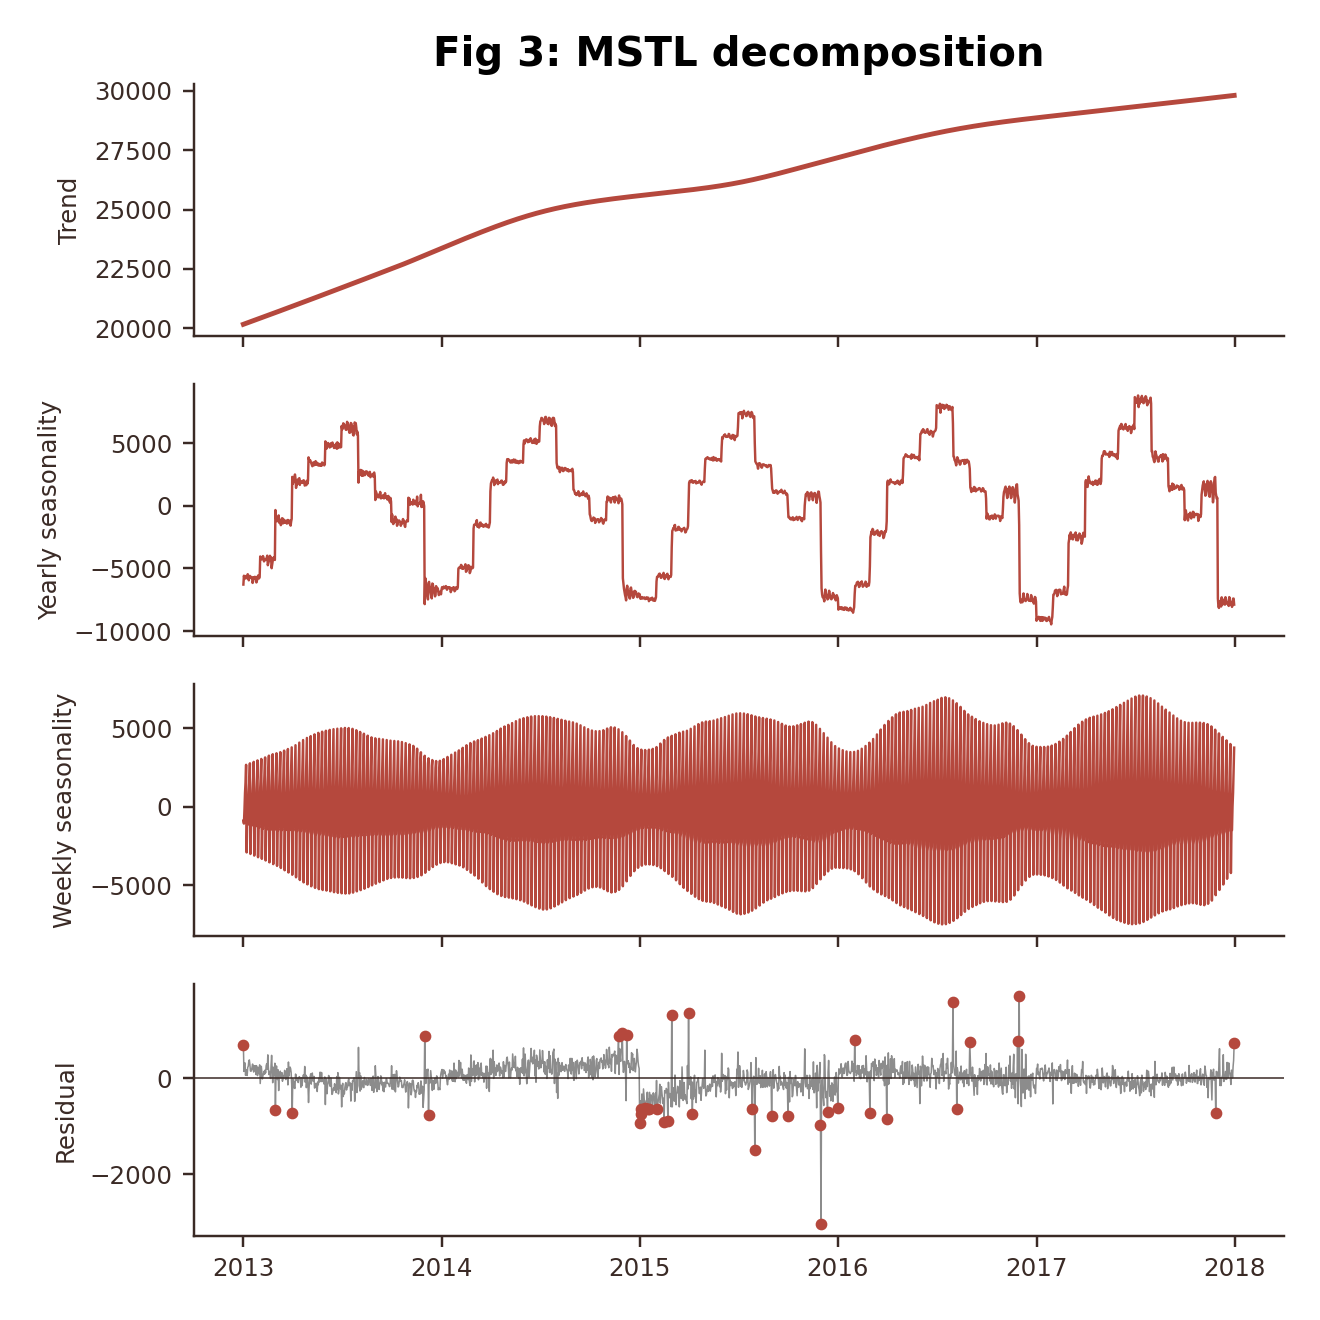

In [ ]:
from IPython.display import Image, display
for f in ["fig1_line", "fig2_missing", "fig3_decomp"]:
    display(Image(f"figs/{f}.png", width=600))